In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os



In [3]:
sitting = pd.read_csv("sitting_Raw Data.csv")
walking = pd.read_csv("walking_Raw Data.csv")
situps = pd.read_csv("situps_Raw Data.csv")

print("SITTING DATA")
print(sitting.head())
print("\nColumns:", sitting.columns.tolist())
print("Shape:", sitting.shape)

print("\n" + "="*50)

print("WALKING DATA")
print(walking.head())
print("\nColumns:", walking.columns.tolist())
print("Shape:", walking.shape)

print("\n" + "="*50)

print("SIT-UPS DATA")
print(situps.head())
print("\nColumns:", situps.columns.tolist())
print("Shape:", situps.shape)

SITTING DATA
   Time (s)  Linear Acceleration x (m/s^2)  Linear Acceleration y (m/s^2)  \
0  0.020280                      -0.012026                       0.287814   
1  0.028280                      -0.037514                       0.189491   
2  0.036283                      -0.025940                       0.257637   
3  0.044283                      -0.062300                       0.394593   
4  0.052284                      -0.092543                       0.473767   

   Linear Acceleration z (m/s^2)  Absolute acceleration (m/s^2)  
0                       0.210193                       0.356598  
1                      -0.348894                       0.398799  
2                      -0.561506                       0.618335  
3                      -0.549141                       0.679074  
4                      -0.445518                       0.656891  

Columns: ['Time (s)', 'Linear Acceleration x (m/s^2)', 'Linear Acceleration y (m/s^2)', 'Linear Acceleration z (m/s^2)', 'Absol

In [4]:
print("Missing values in Sitting:")
print(sitting.isnull().sum())

print("\nMissing values in Walking:")
print(walking.isnull().sum())

print("\nMissing values in Sit-ups:")
print(situps.isnull().sum())

Missing values in Sitting:
Time (s)                         0
Linear Acceleration x (m/s^2)    0
Linear Acceleration y (m/s^2)    0
Linear Acceleration z (m/s^2)    0
Absolute acceleration (m/s^2)    0
dtype: int64

Missing values in Walking:
Time (s)                         0
Linear Acceleration x (m/s^2)    0
Linear Acceleration y (m/s^2)    0
Linear Acceleration z (m/s^2)    0
Absolute acceleration (m/s^2)    0
dtype: int64

Missing values in Sit-ups:
Time (s)                         0
Linear Acceleration x (m/s^2)    0
Linear Acceleration y (m/s^2)    0
Linear Acceleration z (m/s^2)    0
Absolute acceleration (m/s^2)    0
dtype: int64


In [6]:
def calculate_magnitude(df):
    x = df["Linear Acceleration x (m/s^2)"]
    y = df["Linear Acceleration y (m/s^2)"]
    z = df["Linear Acceleration z (m/s^2)"]

    df = df.copy()

    df["Acceleration Magnitude"] = np.sqrt(
        x**2 + y**2 + z**2
    )

    return df


sitting = calculate_magnitude(sitting)
walking = calculate_magnitude(walking)
situps = calculate_magnitude(situps)

print(sitting.head())

   Time (s)  Linear Acceleration x (m/s^2)  Linear Acceleration y (m/s^2)  \
0  0.020280                      -0.012026                       0.287814   
1  0.028280                      -0.037514                       0.189491   
2  0.036283                      -0.025940                       0.257637   
3  0.044283                      -0.062300                       0.394593   
4  0.052284                      -0.092543                       0.473767   

   Linear Acceleration z (m/s^2)  Absolute acceleration (m/s^2)  \
0                       0.210193                       0.356598   
1                      -0.348894                       0.398799   
2                      -0.561506                       0.618335   
3                      -0.549141                       0.679074   
4                      -0.445518                       0.656891   

   Acceleration Magnitude  
0                0.356598  
1                0.398799  
2                0.618335  
3                0.679

In [7]:
comparison = pd.DataFrame({
    "Our Magnitude": sitting["Acceleration Magnitude"].head(10),
    "Phyphox Absolute": sitting["Absolute acceleration (m/s^2)"].head(10)
})

print(comparison)

   Our Magnitude  Phyphox Absolute
0       0.356598          0.356598
1       0.398799          0.398799
2       0.618335          0.618335
3       0.679074          0.679074
4       0.656891          0.656891
5       0.597483          0.597483
6       0.491060          0.491060
7       0.413029          0.413029
8       0.364629          0.364629
9       0.308233          0.308233


In [8]:
def extract_features(df, label, window_size=100):

    magnitude = df["Acceleration Magnitude"].values

    features = []

    # Process data in 100-sample windows
    for start in range(0, len(magnitude) - window_size + 1, window_size):

        window = magnitude[start:start + window_size]

        mean = np.mean(window)
        std = np.std(window)
        rms = np.sqrt(np.mean(window ** 2))

        features.append([mean, std, rms, label])

    return pd.DataFrame(
        features,
        columns=["Mean", "Std", "RMS", "Activity"]
    )

In [9]:
sitting_features = extract_features(sitting, "Sitting")
walking_features = extract_features(walking, "Walking")
situps_features = extract_features(situps, "Sit-ups")

In [10]:
features_df = pd.concat(
    [sitting_features, walking_features, situps_features],
    ignore_index=True
)

print(features_df.head(10))
print("\nShape:", features_df.shape)

       Mean       Std       RMS Activity
0  0.385800  0.259496  0.464951  Sitting
1  0.175385  0.091954  0.198028  Sitting
2  0.184093  0.158058  0.242636  Sitting
3  0.130592  0.101860  0.165619  Sitting
4  0.111205  0.038556  0.117699  Sitting
5  0.127162  0.052038  0.137397  Sitting
6  0.136719  0.062845  0.150471  Sitting
7  0.133219  0.057682  0.145171  Sitting
8  0.125986  0.046483  0.134288  Sitting
9  0.104415  0.040374  0.111949  Sitting

Shape: (707, 4)


In [11]:
print(features_df["Activity"].value_counts())

Activity
Sit-ups    241
Walking    239
Sitting    227
Name: count, dtype: int64


In [12]:
print(features_df.groupby("Activity")[["Mean", "Std", "RMS"]].mean())

              Mean       Std       RMS
Activity                              
Sit-ups   1.622431  0.759944  1.802225
Sitting   0.104903  0.042049  0.113376
Walking   2.245876  1.405109  2.652573


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Input features
X = features_df[["Mean", "Std", "RMS"]]

# Target labels
y = features_df["Activity"]

# Convert activity names to numbers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded classes:", np.unique(y_encoded))

Classes: ['Sit-ups' 'Sitting' 'Walking']
Encoded classes: [0 1 2]


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 565
Testing samples: 142


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (565, 3)
Testing data shape: (142, 3)


In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [17]:
model = keras.Sequential([
    layers.Input(shape=(3,)),

    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),

    layers.Dense(3, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 707 (2.76 KB)

 Trainable params: 707 (2.76 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.5398 - loss: 1.0375 - val_accuracy: 0.7876 - val_loss: 0.9542
Epoch 2/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7743 - loss: 0.8759 - val_accuracy: 0.7699 - val_loss: 0.7983
Epoch 3/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7898 - loss: 0.7266 - val_accuracy: 0.7876 - val_loss: 0.6607
Epoch 4/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7987 - loss: 0.6151 - val_accuracy: 0.7965 - val_loss: 0.5622
Epoch 5/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8208 - loss: 0.5387 - val_accuracy: 0.8053 - val_loss: 0.4972
Epoch 6/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8385 - loss: 0.4872 - val_accuracy: 0.8230 - val_loss: 0.4470
Epoch 7/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8540 - loss: 0.4467 - val_accuracy: 0.8584 - val_loss: 0.4064
Epoch 8/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8673 - loss: 0.4135 - val_accuracy: 0.8850 - val_lo

In [20]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Baseline Test Accuracy: {test_accuracy * 100:.2f}%")

Baseline Test Accuracy: 88.03%


In [21]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

              precision    recall  f1-score   support

     Sit-ups       0.86      0.79      0.83        48
     Sitting       0.92      1.00      0.96        46
     Walking       0.85      0.85      0.85        48

    accuracy                           0.88       142
   macro avg       0.88      0.88      0.88       142
weighted avg       0.88      0.88      0.88       142

Confusion Matrix:
[[38  3  7]
 [ 0 46  0]
 [ 6  1 41]]


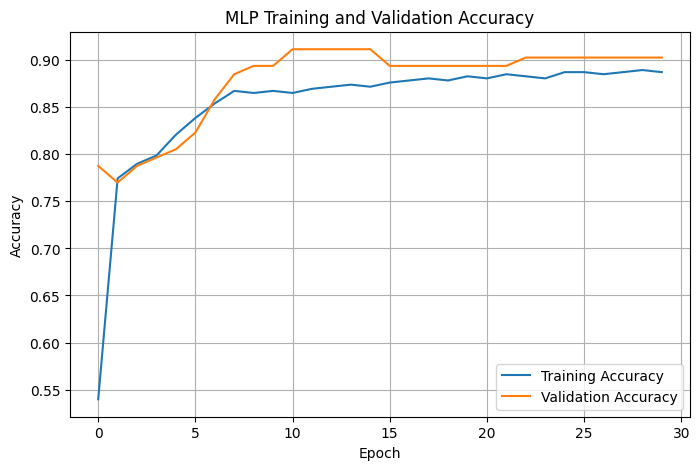

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [23]:
model.save("har_model.keras")

print("Model saved successfully.")

Model saved successfully.


In [24]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_float32 = converter.convert()

with open("har_float32.tflite", "wb") as f:
    f.write(tflite_float32)

print("Float32 TFLite model created.")

Saved artifact at '/tmp/tmpyjgsxtcf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  132127418141776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418143120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418143504: TensorSpec(shape=(), dtype=tf.resource, name=None)
Float32 TFLite model created.


In [25]:
import os

float32_size = os.path.getsize("har_float32.tflite") / 1024

print(f"Float32 Model Size: {float32_size:.2f} KB")

Float32 Model Size: 4.81 KB


In [26]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Enable dynamic range quantization
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_dynamic = converter.convert()

with open("har_dynamic.tflite", "wb") as f:
    f.write(tflite_dynamic)

print("Dynamic Range TFLite model created.")

Saved artifact at '/tmp/tmpa93rdhpf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  132127418141776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418143120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418143504: TensorSpec(shape=(), dtype=tf.resource, name=None)
Dynamic Range TFLite model created.


In [27]:
dynamic_size = os.path.getsize("har_dynamic.tflite") / 1024

print(f"Dynamic Range Model Size: {dynamic_size:.2f} KB")

Dynamic Range Model Size: 4.81 KB


In [28]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]

tflite_float16 = converter.convert()

with open("har_float16.tflite", "wb") as f:
    f.write(tflite_float16)

print("Float16 TFLite model created.")

Saved artifact at '/tmp/tmpm62dqefr'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  132127418141776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418143120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418143504: TensorSpec(shape=(), dtype=tf.resource, name=None)
Float16 TFLite model created.


In [29]:
float16_size = os.path.getsize("har_float16.tflite") / 1024

print(f"Float16 Model Size: {float16_size:.2f} KB")

Float16 Model Size: 4.19 KB


In [30]:
def representative_dataset():
    for i in range(min(100, len(X_train_scaled))):
        sample = X_train_scaled[i:i+1].astype(np.float32)
        yield [sample]

In [31]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Representative calibration data
converter.representative_dataset = representative_dataset

# Force INT8 for inputs and outputs
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_int8 = converter.convert()

with open("har_int8.tflite", "wb") as f:
    f.write(tflite_int8)

print("Full Integer INT8 TFLite model created.")

Saved artifact at '/tmp/tmpt3nujzbx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  132127418141776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418143120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418142928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132127418143504: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Full Integer INT8 TFLite model created.


In [32]:
int8_size = os.path.getsize("har_int8.tflite") / 1024

print(f"Full INT8 Model Size: {int8_size:.2f} KB")

Full INT8 Model Size: 4.37 KB


In [33]:
import time

def evaluate_tflite_model(model_path, X_test_data, y_test_data):

    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    input_index = input_details[0]["index"]
    output_index = output_details[0]["index"]

    input_dtype = input_details[0]["dtype"]
    output_dtype = output_details[0]["dtype"]

    input_scale, input_zero_point = input_details[0]["quantization"]
    output_scale, output_zero_point = output_details[0]["quantization"]

    predictions = []
    inference_times = []

    for sample in X_test_data:

        sample = sample.reshape(1, -1).astype(np.float32)

        # Convert input for INT8 model
        if input_dtype == np.int8:
            sample = np.round(
                sample / input_scale + input_zero_point
            ).astype(np.int8)

        start = time.perf_counter()

        interpreter.set_tensor(input_index, sample)
        interpreter.invoke()

        end = time.perf_counter()

        output = interpreter.get_tensor(output_index)

        # Convert INT8 output back to float
        if output_dtype == np.int8:
            output = (
                output.astype(np.float32) - output_zero_point
            ) * output_scale

        predictions.append(np.argmax(output, axis=1)[0])

        inference_times.append((end - start) * 1_000_000)

    accuracy = np.mean(
        np.array(predictions) == np.array(y_test_data)
    ) * 100

    avg_time = np.mean(inference_times)

    model_size = os.path.getsize(model_path) / 1024

    return accuracy, avg_time, model_size

In [34]:
models = {
    "Float32": "har_float32.tflite",
    "Dynamic Range": "har_dynamic.tflite",
    "Float16": "har_float16.tflite",
    "Full INT8": "har_int8.tflite"
}

results = {}

for name, path in models.items():

    accuracy, inference_time, size = evaluate_tflite_model(
        path,
        X_test_scaled,
        y_test
    )

    results[name] = {
        "Accuracy (%)": accuracy,
        "Inference Time (µs)": inference_time,
        "Model Size (KB)": size
    }

    print(f"\n{name}")
    print(f"Accuracy: {accuracy:.2f}%")
    print(f"Inference Time: {inference_time:.2f} µs")
    print(f"Model Size: {size:.2f} KB")


Float32
Accuracy: 88.03%
Inference Time: 14.06 µs
Model Size: 4.81 KB

Dynamic Range
Accuracy: 88.03%
Inference Time: 6.34 µs
Model Size: 4.81 KB

Float16
Accuracy: 88.03%
Inference Time: 3.12 µs
Model Size: 4.19 KB

Full INT8
Accuracy: 88.03%
Inference Time: 4.94 µs
Model Size: 4.37 KB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [35]:
baseline_size = float32_size

for name in results:
    results[name]["Memory Reduction (%)"] = (
        (baseline_size - results[name]["Model Size (KB)"])
        / baseline_size
    ) * 100

results_df = pd.DataFrame(results).T

print(results_df)

               Accuracy (%)  Inference Time (µs)  Model Size (KB)  \
Float32           88.028169            14.056810         4.812500   
Dynamic Range     88.028169             6.339070         4.812500   
Float16           88.028169             3.116711         4.191406   
Full INT8         88.028169             4.944923         4.367188   

               Memory Reduction (%)  
Float32                    0.000000  
Dynamic Range              0.000000  
Float16                   12.905844  
Full INT8                  9.253247  


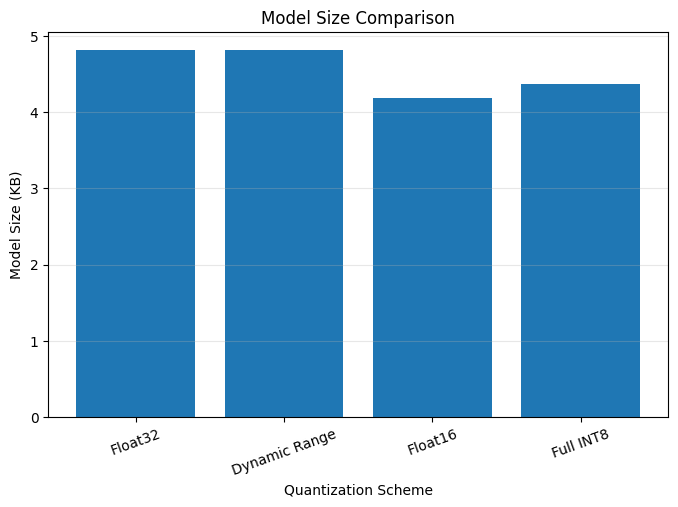

In [36]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df.index,
    results_df["Model Size (KB)"]
)

plt.xlabel("Quantization Scheme")
plt.ylabel("Model Size (KB)")
plt.title("Model Size Comparison")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

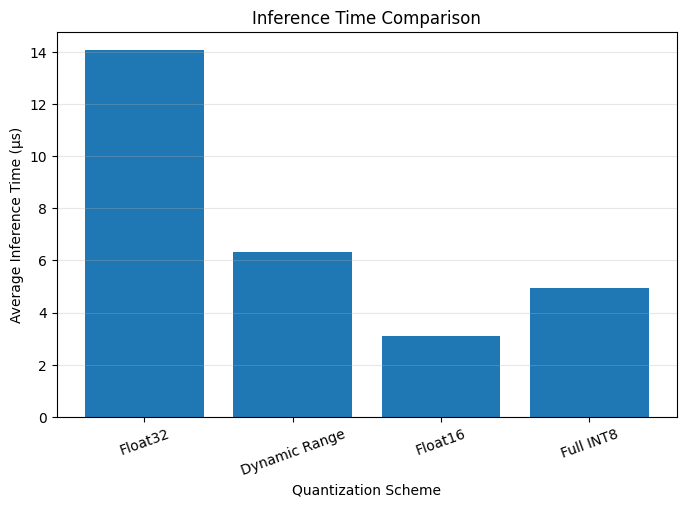

In [37]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df.index,
    results_df["Inference Time (µs)"]
)

plt.xlabel("Quantization Scheme")
plt.ylabel("Average Inference Time (µs)")
plt.title("Inference Time Comparison")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

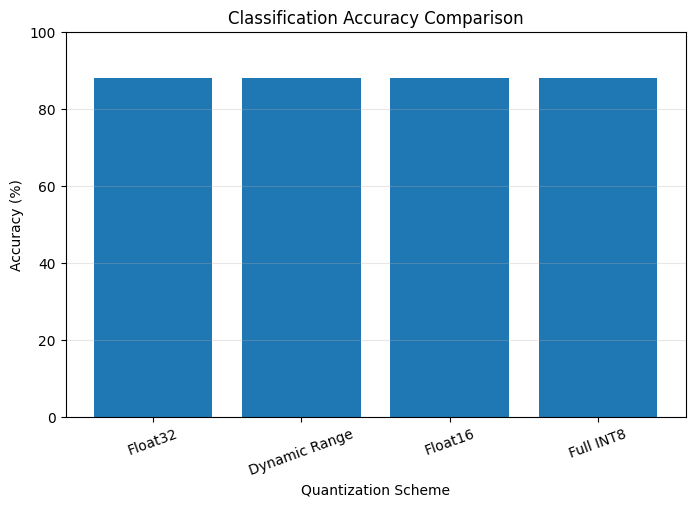

In [38]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df.index,
    results_df["Accuracy (%)"]
)

plt.xlabel("Quantization Scheme")
plt.ylabel("Accuracy (%)")
plt.title("Classification Accuracy Comparison")

plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

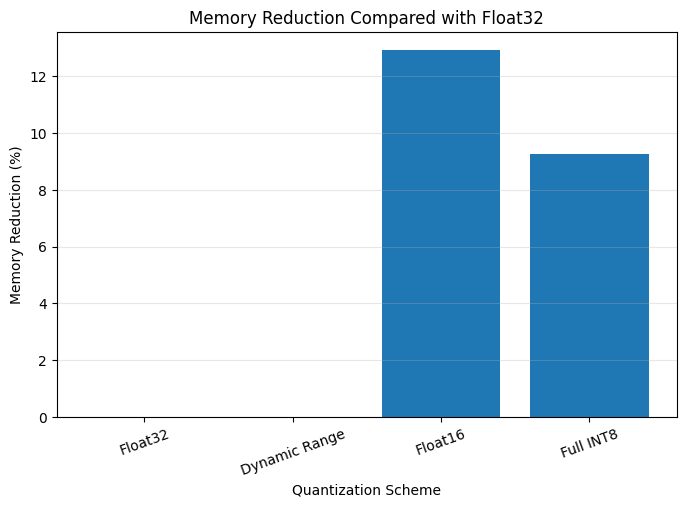

In [39]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df.index,
    results_df["Memory Reduction (%)"]
)

plt.xlabel("Quantization Scheme")
plt.ylabel("Memory Reduction (%)")
plt.title("Memory Reduction Compared with Float32")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [40]:
results_df.round(2)

,Accuracy (%),Inference Time (µs),Model Size (KB),Memory Reduction (%)
Float32,88.03,14.06,4.81,0.00
Dynamic Range,88.03,6.34,4.81,0.00
Float16,88.03,3.12,4.19,12.91
Full INT8,88.03,4.94,4.37,9.25


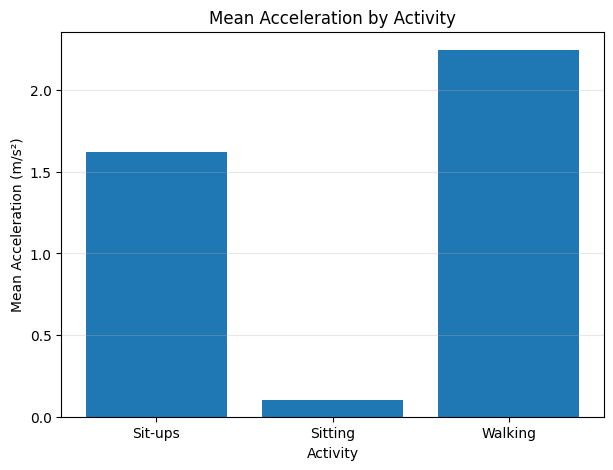

In [41]:
activity_means = features_df.groupby("Activity")["Mean"].mean()

plt.figure(figsize=(7, 5))

plt.bar(activity_means.index, activity_means.values)

plt.xlabel("Activity")
plt.ylabel("Mean Acceleration (m/s²)")
plt.title("Mean Acceleration by Activity")

plt.grid(axis="y", alpha=0.3)
plt.show()

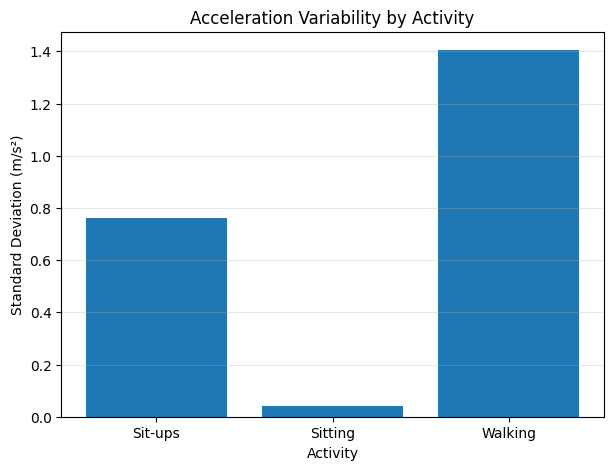

In [42]:
activity_std = features_df.groupby("Activity")["Std"].mean()

plt.figure(figsize=(7, 5))

plt.bar(activity_std.index, activity_std.values)

plt.xlabel("Activity")
plt.ylabel("Standard Deviation (m/s²)")
plt.title("Acceleration Variability by Activity")

plt.grid(axis="y", alpha=0.3)
plt.show()

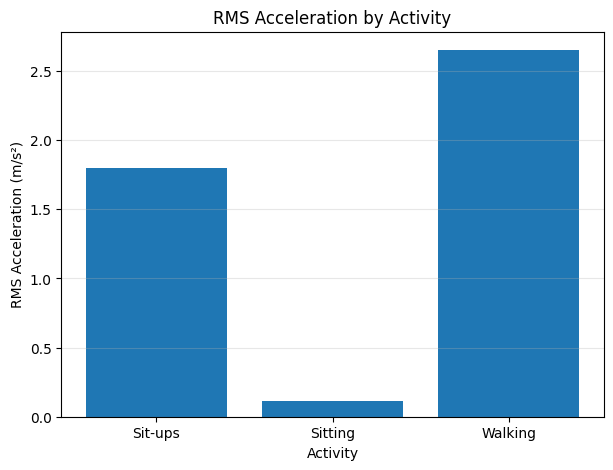

In [43]:
activity_rms = features_df.groupby("Activity")["RMS"].mean()

plt.figure(figsize=(7, 5))

plt.bar(activity_rms.index, activity_rms.values)

plt.xlabel("Activity")
plt.ylabel("RMS Acceleration (m/s²)")
plt.title("RMS Acceleration by Activity")

plt.grid(axis="y", alpha=0.3)
plt.show()